<a href="https://colab.research.google.com/github/tmachingur-code/predicting-crop-yield-rwanda/blob/main/notebooks/Predicting_Crop_Yield_Rwanda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 1: Imports

In [ ]:
# Project: Predicting Crop Yield in Rwanda
# Stage 1: Environment setup

import re, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_absolute_error, f1_score, accuracy_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Step 2: Tell it where the zips are

In [ ]:
import os
from pathlib import Path

# Where the three NISR zip files live.
# - On Colab: the Google Drive folder below.
# - Elsewhere: ../data/raw, or the folder in the CROP_DATA_DIR environment variable.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/rwanda_sas_zips')
except ImportError:
    DATA_DIR = Path(os.environ.get("CROP_DATA_DIR", "../data/raw"))

print("Folder exists:", DATA_DIR.exists())
for z in sorted(DATA_DIR.glob("*.zip")):
    print(z.name)

Mounted at /content/drive
Folder exists: True
Season_A__Agricultural_Practice.zip
Season_A__Crop_production.zip
Season_A__Fertilizers___Pesticides.zip


## Step 3: Load the files

In [ ]:
def table_of(csv_name):
    n = csv_name.lower()
    if "production" in n:            return "crop"
    if "fertilizer" in n:            return "fert"
    if "agricultural_practice" in n: return "practice"
    if "antierosion" in n:           return "screen"
    return "unknown"

raw, meta = {}, {}
for z in sorted(DATA_DIR.glob("*.zip")):
    zf = zipfile.ZipFile(z)
    names = zf.namelist()
    csv = [n for n in names if n.lower().endswith(".csv") and "metadata" not in n.lower()][0]
    readme = [n for n in names if n.lower().endswith("readme.txt")][0]
    m = re.search(r"(20\d\d)/(20\d\d)", zf.read(readme).decode("utf8", "ignore"))
    year = f"{m.group(1)}/{m.group(2)[2:]}"
    df = pd.read_csv(zf.open(csv), low_memory=False)
    df.columns = df.columns.str.lower()
    key = (year, table_of(csv))
    raw[key] = df
    meta_name = [n for n in names if n.lower().endswith("metadata.csv")]
    if meta_name:
        meta[key] = pd.read_csv(zf.open(meta_name[0]))

summary = pd.Series({k: len(v) for k, v in raw.items()}, name="rows").rename_axis(["year", "table"]).reset_index()
summary.pivot(index="table", columns="year", values="rows")

year,2021/22
table,
crop,41589
fert,24279
practice,17376


## Step 4: Crop names and a lookup helper

In [ ]:
CROP_NAMES = {1:"Maize", 2:"Sorghum", 3:"Paddy rice", 4:"Wheat", 5:"Other cereals", 6:"Sweet potato",
              7:"Irish potato", 8:"Taro & yams", 9:"Cassava", 10:"Bush bean", 11:"Climbing bean",
              12:"Pea", 13:"Groundnut", 14:"Soybean", 15:"Cooking banana", 16:"Dessert banana",
              17:"Banana for beer", 18:"Vegetables", 19:"Fruits", 20:"Fodder crops", 21:"Other crops"}

def describe(year, table, col):
    m = meta[(year, table)]
    return m.loc[m.iloc[:, 0].str.lower() == col.lower()].to_string(index=False, header=False)

describe("2021/22", "practice", "s4q1")

's4q1 INT Numeric code representing the degree of erosion on this plot: 1 = Severe (Rill erosion, Gully erosion, Mass movement/landslides), 2 = Moderate (Diffuse overland flow Erosion, Overland flow erosion,erosion by Infiltration), 3 = Low (Wind erosion), 4 = Very Low (Splash erosion).'

## Step 5: Merge the three 2021/22 tables

In [ ]:
KEY = ["segment_id", "s1q6", "s2q1"]

def build_2122(raw, year="2021/22"):
    crop, fert, prac = raw[(year, "crop")].copy(), raw[(year, "fert")], raw[(year, "practice")]

    g = fert.groupby(KEY)
    fert_plot = pd.DataFrame({
        "organic":          g["s3q3"].apply(lambda s: (s == 1).any()),
        "inorganic":        g["s3q9"].apply(lambda s: (s == 1).any()),
        "pesticide":        g["s3q19"].apply(lambda s: (s == 1).any()),
        "n_inorg_products": g["s3q10"].apply(lambda s: s[s.notna() & (s != 99)].nunique()),
    }).astype(int).reset_index()

    prac_plot = prac[KEY + ["s4q1", "s4q3", "s4q6", "s4q15"]].rename(columns={
        "s4q1": "erosion", "s4q3": "anti_erosion", "s4q6": "consolidation", "s4q15": "irrigated"})

    df = crop.merge(fert_plot, on=KEY, how="left").merge(prac_plot, on=KEY, how="left")
    assert len(df) == len(crop), "merge changed the row count"
    df["n_crops_on_plot"] = df.groupby(KEY)["cropcategory"].transform("count")
    df["single_crop_plot"] = df["n_crops_on_plot"] == 1
    df["year"] = year
    return df

df = build_2122(raw)
print("rows:", len(df), "| with fertilizer info:", round(df["organic"].notna().mean(), 3),
      "| with practice info:", round(df["erosion"].notna().mean(), 3))
print("share of crop rows on single-crop plots:", round(df["single_crop_plot"].mean(), 3))
df[["segment_id","s1q6","s2q1","cropcategory","yield","harv_area","organic","inorganic",
    "pesticide","erosion","anti_erosion","consolidation","irrigated"]].head()

rows: 41589 | with fertilizer info: 0.996 | with practice info: 1.0
share of crop rows on single-crop plots: 0.13


,segment_id,s1q6,s2q1,cropcategory,yield,harv_area,organic,inorganic,pesticide,erosion,anti_erosion,consolidation,irrigated
0,12001.0,1,41,10,960.008118,0.104166,1.0,0.0,0.0,3.0,1.0,2.0,1.0
1,12001.0,1,40,10,1269.844971,0.425249,1.0,0.0,0.0,3.0,1.0,2.0,1.0
2,12001.0,1,60,6,15271.156250,0.155849,1.0,0.0,0.0,3.0,1.0,2.0,2.0
3,12001.0,1,38,18,34988.839844,0.089371,1.0,0.0,0.0,3.0,1.0,2.0,1.0
4,12001.0,1,40,18,29982.449219,0.283499,1.0,0.0,0.0,3.0,1.0,2.0,1.0


## Step 6: Cleaning

In [ ]:
n0 = len(df)
no_yield = df["yield"].isna().sum()
zero_yield = (df["yield"] <= 0).sum()
data = df[df["yield"].notna() & (df["yield"] > 0)].copy()
counts = data["cropcategory"].value_counts()
MAIN_CROPS = counts[counts >= 300].index.tolist()
data = data[data["cropcategory"].isin(MAIN_CROPS)].reset_index(drop=True)
print(f"rows: {n0} | missing yield: {no_yield} | zero yield: {zero_yield} | kept: {len(data)} across {len(MAIN_CROPS)} crops")
print("yield (kg/ha) quantiles:", data["yield"].quantile([.01, .5, .9, .99, 1]).round(0).to_dict())

rows: 41589 | missing yield: 4381 | zero yield: 1319 | kept: 34894 across 16 crops
yield (kg/ha) quantiles: {0.01: 121.0, 0.5: 1801.0, 0.9: 13912.0, 0.99: 22163.0, 1.0: 146835.0}


## Step 7: Features and the relative-yield target

In [ ]:
LOC      = ["s1q1", "s1q2", "s1q3"]
FARMER   = ["s1q7", "s1q8", "s1q9"]
PLOT     = ["s2q2"]
PRACTICE = ["organic", "inorganic", "pesticide", "n_inorg_products",
            "erosion", "anti_erosion", "consolidation", "irrigated"]
FEATURES    = ["cropcategory"] + LOC + FARMER + PLOT + PRACTICE
CATEGORICAL = ["cropcategory", "s1q1", "s1q2", "s1q3"]

def make_target(train, test, cap_q=0.99):
    # caps and crop medians come from the training rows only
    caps = train.groupby("cropcategory")["yield"].quantile(cap_q)
    def log_capped(d):
        return np.log(d["yield"].clip(upper=d["cropcategory"].map(caps)))
    lt_tr, lt_te = log_capped(train), log_capped(test)
    med = lt_tr.groupby(train["cropcategory"]).median()
    b_tr, b_te = train["cropcategory"].map(med), test["cropcategory"].map(med)
    return lt_tr - b_tr, lt_te - b_te, b_tr, b_te

## Step 8: EDA

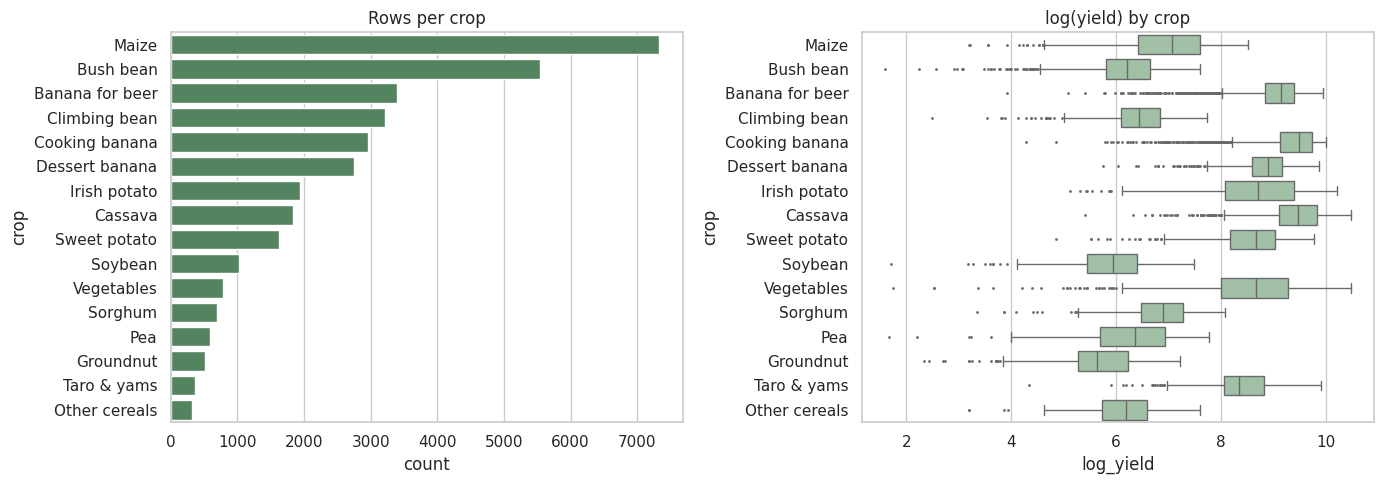

In [ ]:
caps_all = data.groupby("cropcategory")["yield"].transform(lambda s: s.quantile(0.99))
eda = data.copy()
eda["log_yield"] = np.log(eda["yield"].clip(upper=caps_all))
eda["rel"] = eda["log_yield"] - eda.groupby("cropcategory")["log_yield"].transform("median")
eda["crop"] = eda["cropcategory"].map(CROP_NAMES)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
order = eda["crop"].value_counts().index
sns.countplot(data=eda, y="crop", order=order, ax=ax[0], color="#4C8C5A"); ax[0].set_title("Rows per crop")
sns.boxplot(data=eda, y="crop", x="log_yield", order=order, ax=ax[1], color="#9CC5A1", fliersize=1)
ax[1].set_title("log(yield) by crop")
plt.tight_layout(); plt.show()

In [ ]:
miss = data[FEATURES].isna().mean().sort_values(ascending=False)
print(miss.round(3).to_string())

irrigated           0.917
anti_erosion        0.075
s1q9                0.016
s1q8                0.016
inorganic           0.004
organic             0.004
pesticide           0.004
n_inorg_products    0.004
erosion             0.000
consolidation       0.000
s2q2                0.000
s1q7                0.000
s1q1                0.000
cropcategory        0.000
s1q2                0.000
s1q3                0.000


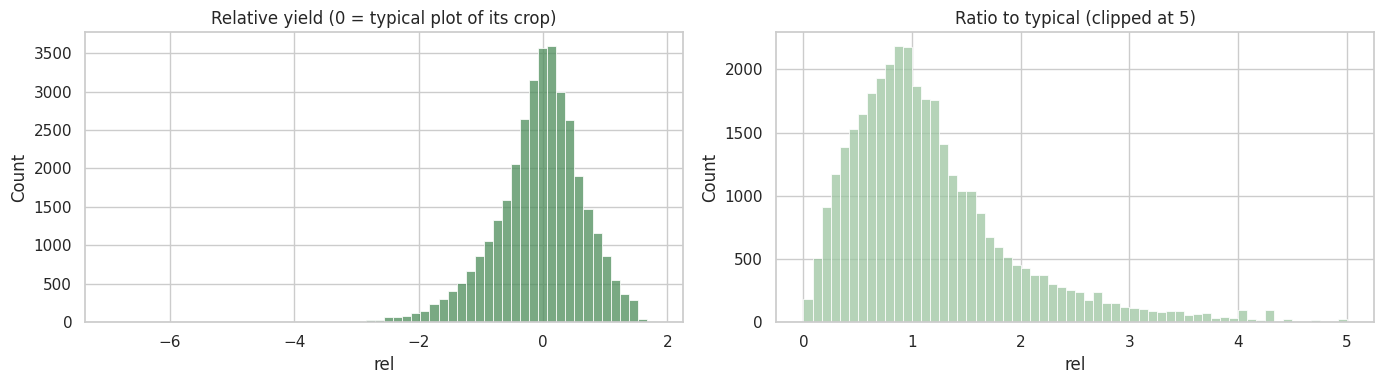

crop,Bush bean,Cassava,Maize
erosion,,,
1.0,-0.210,-0.036,-0.193
2.0,-0.054,-0.013,-0.103
3.0,-0.016,0.015,-0.033
4.0,0.038,0.045,0.056


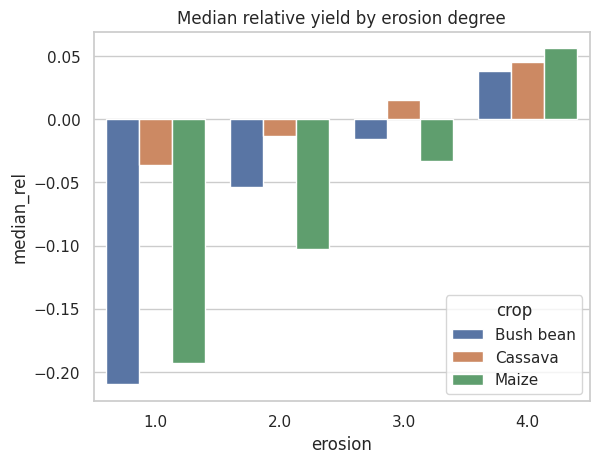

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(eda["rel"], bins=60, ax=ax[0], color="#4C8C5A"); ax[0].set_title("Relative yield (0 = typical plot of its crop)")
sns.histplot(np.exp(eda["rel"]).clip(upper=5), bins=60, ax=ax[1], color="#9CC5A1"); ax[1].set_title("Ratio to typical (clipped at 5)")
plt.tight_layout(); plt.show()

main3 = {1: "Maize", 10: "Bush bean", 9: "Cassava"}
tab = (eda[eda["cropcategory"].isin(main3)].groupby(["crop", "erosion"])["rel"]
       .agg(n="count", median_rel="median").round(3).reset_index())
display(tab.pivot(index="erosion", columns="crop", values="median_rel"))
sns.barplot(data=tab, x="erosion", y="median_rel", hue="crop"); plt.title("Median relative yield by erosion degree"); plt.show()

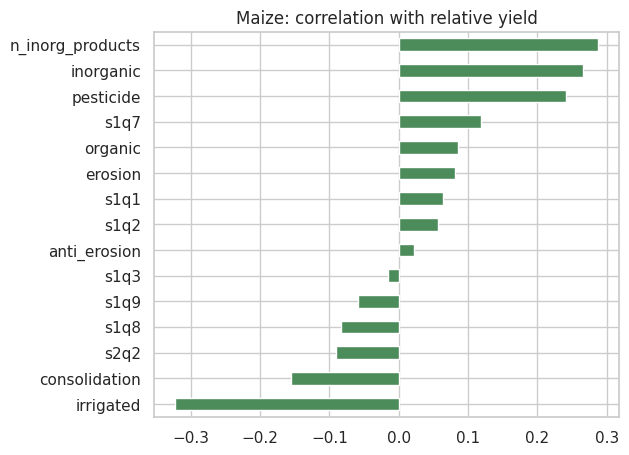

In [ ]:
mz = eda[eda["cropcategory"] == 1]
num = [c for c in FEATURES if c != "cropcategory"]
cor = mz[num + ["rel"]].corr(method="spearman")["rel"].drop("rel").sort_values()
cor.plot.barh(figsize=(6, 5), color="#4C8C5A"); plt.title("Maize: correlation with relative yield"); plt.show()

## Step 9: The quick check

In [ ]:
def make_model(features, kind="flexible"):
    cat = [f in CATEGORICAL for f in features]
    if kind == "simple":
        return HistGradientBoostingRegressor(max_iter=100, learning_rate=0.05, max_depth=3, min_samples_leaf=50,
                                             categorical_features=cat, random_state=RANDOM_STATE)
    return HistGradientBoostingRegressor(max_iter=250, learning_rate=0.05, categorical_features=cat,
                                         random_state=RANDOM_STATE)

def run_cv(d, features, kind="flexible", n_splits=5):
    d = d.reset_index(drop=True)
    oof = np.full(len(d), np.nan); base = np.full(len(d), np.nan); rel = np.full(len(d), np.nan)
    train_r2 = []
    for tr, te in GroupKFold(n_splits).split(d, groups=d["segment_id"]):
        dtr, dte = d.iloc[tr], d.iloc[te]
        y_tr, y_te, b_tr, b_te = make_target(dtr, dte)
        ok_tr = y_tr.notna()
        m = make_model(features, kind).fit(dtr.loc[ok_tr, features], y_tr[ok_tr])
        train_r2.append(r2_score(y_tr[ok_tr], m.predict(dtr.loc[ok_tr, features])))
        oof[te], base[te], rel[te] = m.predict(dte[features]), b_te.values, y_te.values
    ok = ~np.isnan(rel) & ~np.isnan(oof)
    return dict(n=int(ok.sum()), test_r2=r2_score(rel[ok], oof[ok]), dumb_r2=r2_score(rel[ok], np.zeros(ok.sum())),
                train_r2=float(np.mean(train_r2)),
                mae_model=mean_absolute_error(d["yield"][ok], np.exp(base[ok] + oof[ok])),
                mae_dumb=mean_absolute_error(d["yield"][ok], np.exp(base[ok])),
                frame=pd.DataFrame({"cropcategory": d["cropcategory"][ok].values, "rel": rel[ok], "pred": oof[ok]}))

rows = []
for code_, name in [(1, "Maize"), (10, "Bush bean"), (9, "Cassava")]:
    for subset in ["all plots", "single-crop plots only"]:
        d = data[data["cropcategory"] == code_]
        if subset != "all plots":
            d = d[d["single_crop_plot"]]
        feats = [f for f in FEATURES if f != "cropcategory"]
        for kind in ["simple", "flexible"]:
            r = run_cv(d, feats, kind)
            rows.append(dict(crop=name, subset=subset, model=kind, n=r["n"], test_R2=r["test_r2"], dumb_R2=r["dumb_r2"],
                             train_R2=r["train_r2"], MAE_model_kgha=r["mae_model"], MAE_dumb_kgha=r["mae_dumb"]))
quick = pd.DataFrame(rows).round(3)
quick

,crop,subset,model,n,test_R2,dumb_R2,train_R2,MAE_model_kgha,MAE_dumb_kgha
0,Maize,all plots,simple,7319,0.170,-0.010,0.242,778.125,857.280
1,Maize,all plots,flexible,7319,0.133,-0.010,0.509,787.993,857.280
2,Maize,single-crop plots only,simple,791,0.225,-0.013,0.414,994.432,1164.710
3,Maize,single-crop plots only,flexible,791,0.080,-0.013,0.868,1047.667,1164.710
4,Bush bean,all plots,simple,5533,0.102,-0.001,0.184,264.621,282.708
5,Bush bean,all plots,flexible,5533,0.054,-0.001,0.513,269.726,282.708
6,Bush bean,single-crop plots only,simple,312,-0.033,-0.000,0.257,294.471,290.980
7,Bush bean,single-crop plots only,flexible,312,-0.232,-0.000,0.752,315.811,290.980
8,Cassava,all plots,simple,1828,0.230,-0.013,0.327,4357.119,5433.348
9,Cassava,all plots,flexible,1828,0.113,-0.013,0.792,4729.802,5433.348


In [ ]:
def verdict(r2):
    return "continue with yield" if r2 >= 0.2 else ("switch target / report limits" if r2 < 0.1 else "in between: refine, then decide")
best = quick.groupby("crop")["test_R2"].max()
pd.DataFrame({"best test R2": best.round(3), "rule of thumb says": best.map(verdict)})

,best test R2,rule of thumb says
crop,,
Bush bean,0.102,"in between: refine, then decide"
Cassava,0.230,continue with yield
Maize,0.225,continue with yield


In [ ]:
allm = run_cv(data, FEATURES, "flexible")
print(f"All main crops pooled: n={allm['n']}, test R2 = {allm['test_r2']:.3f}, train R2 = {allm['train_r2']:.3f}")
f = allm["frame"]; f["crop"] = f["cropcategory"].map(CROP_NAMES)
per_crop = f.groupby("crop").apply(lambda g: pd.Series({"n": len(g), "test_R2": r2_score(g["rel"], g["pred"])}))
per_crop.sort_values("n", ascending=False).head(8).round(3)

All main crops pooled: n=34894, test R2 = 0.145, train R2 = 0.293


,n,test_R2
crop,,
Maize,7319.0,0.177
Bush bean,5533.0,0.084
Banana for beer,3395.0,0.038
Climbing bean,3216.0,0.120
Cooking banana,2965.0,0.171
Dessert banana,2746.0,0.018
Irish potato,1933.0,0.326
Cassava,1828.0,0.154


## Step 10: Classification backup

In [ ]:
def run_cls(d, features, n_splits=5):
    d = d.reset_index(drop=True)
    pred = np.full(len(d), -1); truth = np.full(len(d), -1); majority = np.full(len(d), -1)
    for tr, te in GroupKFold(n_splits).split(d, groups=d["segment_id"]):
        dtr, dte = d.iloc[tr], d.iloc[te]
        y_tr, y_te, _, _ = make_target(dtr, dte)
        lab_tr, lab_te = (y_tr > 0).astype(int), (y_te > 0).astype(int)
        m = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=4, min_samples_leaf=50,
                                           categorical_features=[f in CATEGORICAL for f in features],
                                           random_state=RANDOM_STATE).fit(dtr[features], lab_tr)
        pred[te], truth[te], majority[te] = m.predict(dte[features]), lab_te.values, int(lab_tr.mean() >= 0.5)
    return truth, pred, majority

rows = []
for code_, name in [(1, "Maize"), (10, "Bush bean"), (9, "Cassava")]:
    d = data[data["cropcategory"] == code_]
    truth, pred, maj = run_cls(d, [f for f in FEATURES if f != "cropcategory"])
    rows.append(dict(crop=name, n=len(d), accuracy=accuracy_score(truth, pred), baseline_accuracy=accuracy_score(truth, maj),
                     F1=f1_score(truth, pred), baseline_F1=f1_score(truth, maj, zero_division=0)))
pd.DataFrame(rows).round(3)

## Step 11: What drives the maize model

held-out R2: 0.137


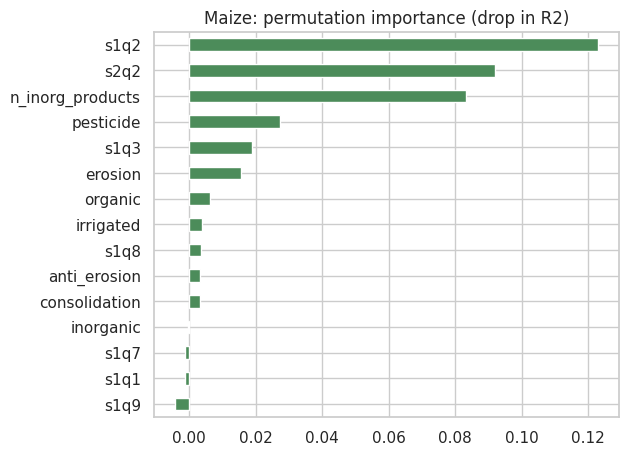

In [ ]:
mz = data[data["cropcategory"] == 1].reset_index(drop=True)
feats = [f for f in FEATURES if f != "cropcategory"]
segs = mz["segment_id"].unique(); rng = np.random.RandomState(RANDOM_STATE)
test_segs = rng.choice(segs, len(segs) // 4, replace=False)
te_mask = mz["segment_id"].isin(test_segs).values
dtr, dte = mz[~te_mask], mz[te_mask]
y_tr, y_te, _, _ = make_target(dtr, dte)
m = make_model(feats, "flexible").fit(dtr[feats], y_tr)
print("held-out R2:", round(r2_score(y_te, m.predict(dte[feats])), 3))
pi = permutation_importance(m, dte[feats], y_te, n_repeats=5, random_state=RANDOM_STATE, scoring="r2")
imp = pd.Series(pi.importances_mean, index=feats).sort_values()
imp.plot.barh(figsize=(6, 5), color="#4C8C5A"); plt.title("Maize: permutation importance (drop in R2)"); plt.show()